# Customer 360 Intelligence - Practical Machine Learning Workshop
### NileConnect | Part F - PCA & Anomaly Detection

## 1. Imports

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 2. Load Dataset

In [2]:
df = pd.read_csv("customer_360_ml_workshop.csv")
df.head()

,CustomerID,Age,Region,TenureMonths,ContractType,InternetType,MonthlyUsageGB,MonthlyChargeEGP,NumServices,SupportCalls6M,LatePayments12M,PaperlessBilling,AutoPay,SatisfactionScore,Future12MRevenueEGP,Churn
0,CUST-00001,22,Alexandria,23,Month-to-month,DSL,317.9,580.48,5,5,0,Yes,Yes,5.0,6287.08,Yes
1,CUST-00002,59,Upper Egypt,9,Month-to-month,4G/5G,359.3,434.36,1,1,1,No,Yes,4.0,4619.91,No
2,CUST-00003,52,Giza,21,Month-to-month,DSL,176.9,391.35,3,5,1,Yes,Yes,5.0,4512.25,No
3,CUST-00004,41,Giza,12,Month-to-month,DSL,312.5,420.40,3,2,1,No,Yes,5.0,3809.65,No
4,CUST-00005,40,Delta,21,Month-to-month,4G/5G,191.6,462.73,3,4,0,No,Yes,3.0,4731.09,No


## 3. Standardized Segmentation Data

In [3]:
cluster_features = ["TenureMonths", "MonthlyUsageGB", "MonthlyChargeEGP", "NumServices",
                    "SupportCalls6M", "LatePayments12M", "SatisfactionScore"]

X_cluster = df[cluster_features]

cluster_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_scaled = cluster_preprocessor.fit_transform(X_cluster)

print("Standardized segmentation data shape:", X_scaled.shape)

Standardized segmentation data shape: (3000, 7)


## 4. PCA with Two Components

In [4]:
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_scaled)

explained_variance = pd.Series(
    pca.explained_variance_ratio_,
    index=["PC1", "PC2"]
)
print("Explained variance ratio per component:")
print(explained_variance.round(4))
print()
print("Total variance explained by PC1 + PC2:", round(explained_variance.sum() * 100, 2), "%")

Explained variance ratio per component:
PC1    0.2624
PC2    0.1495
dtype: float64

Total variance explained by PC1 + PC2: 41.2 %


### Recreating the K-Means segments

In [5]:
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
df["Cluster_KMeans"] = kmeans_final.fit_predict(X_scaled)

cluster_business_names = {
    0: "At-Risk / Late-Payment Customers",
    1: "Loyal Long-Tenured Customers",
    2: "Low-Value Basic Users",
    3: "High-Value Power Users"
}
df["CustomerSegment"] = df["Cluster_KMeans"].map(cluster_business_names)

print(df["CustomerSegment"].value_counts())

CustomerSegment
Low-Value Basic Users               1041
High-Value Power Users               979
At-Risk / Late-Payment Customers     518
Loyal Long-Tenured Customers         462
Name: count, dtype: int64


### PC1/PC2 scatter plot colored by segment

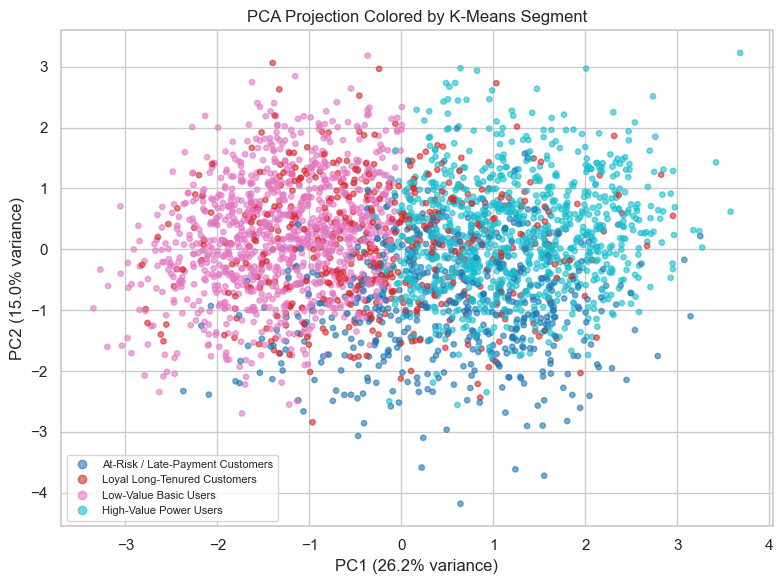

In [6]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(pca_coords[:, 0], pca_coords[:, 1], c=df["Cluster_KMeans"], cmap="tab10", alpha=0.6, s=15)
plt.xlabel(f"PC1 ({explained_variance['PC1'] * 100:.1f}% variance)")
plt.ylabel(f"PC2 ({explained_variance['PC2'] * 100:.1f}% variance)")
plt.title("PCA Projection Colored by K-Means Segment")
plt.legend(handles=scatter.legend_elements()[0], labels=[cluster_business_names[i] for i in sorted(cluster_business_names)],
           loc="best", fontsize=8)
plt.tight_layout()
plt.show()

## 5. Isolation Forest

In [7]:
isolation_forest = IsolationForest(n_estimators=200, contamination=0.05, random_state=42)
anomaly_labels = isolation_forest.fit_predict(X_scaled)
anomaly_scores = isolation_forest.decision_function(X_scaled)

df["AnomalyLabel"] = anomaly_labels
df["AnomalyScore"] = anomaly_scores
df["AnomalyFlag"] = np.where(df["AnomalyLabel"] == -1, "Yes", "No")

print(df["AnomalyFlag"].value_counts())
print("Share flagged as anomalies:", round((df["AnomalyFlag"] == "Yes").mean() * 100, 2), "%")

AnomalyFlag
No     2850
Yes     150
Name: count, dtype: int64
Share flagged as anomalies: 5.0 %


### Profiling anomalies vs normal customers

Average behavior, churn rate and future revenue for the two groups.

In [8]:
anomaly_profile = df.groupby("AnomalyFlag")[cluster_features].mean().round(2)
anomaly_profile["Count"] = df["AnomalyFlag"].value_counts()
anomaly_profile["ChurnRate_%"] = (df.groupby("AnomalyFlag")["Churn"].apply(lambda s: (s == "Yes").mean() * 100)).round(2)
anomaly_profile["AvgFutureRevenue"] = df.groupby("AnomalyFlag")["Future12MRevenueEGP"].mean().round(2)
anomaly_profile

,TenureMonths,MonthlyUsageGB,MonthlyChargeEGP,NumServices,SupportCalls6M,LatePayments12M,SatisfactionScore,Count,ChurnRate_%,AvgFutureRevenue
AnomalyFlag,,,,,,,,,,
No,24.85,229.35,486.48,3.52,2.15,1.06,3.51,2850,17.96,5349.80
Yes,38.58,244.66,503.73,3.51,3.23,1.99,2.95,150,21.33,5576.83


### Where do anomalies fall across the segments?

A crosstab of segment vs anomaly flag.

In [9]:
pd.crosstab(df["CustomerSegment"], df["AnomalyFlag"])

AnomalyFlag,No,Yes
CustomerSegment,,
At-Risk / Late-Payment Customers,475,43
High-Value Power Users,956,23
Low-Value Basic Users,1010,31
Loyal Long-Tenured Customers,409,53


### Anomalies on the PCA projection

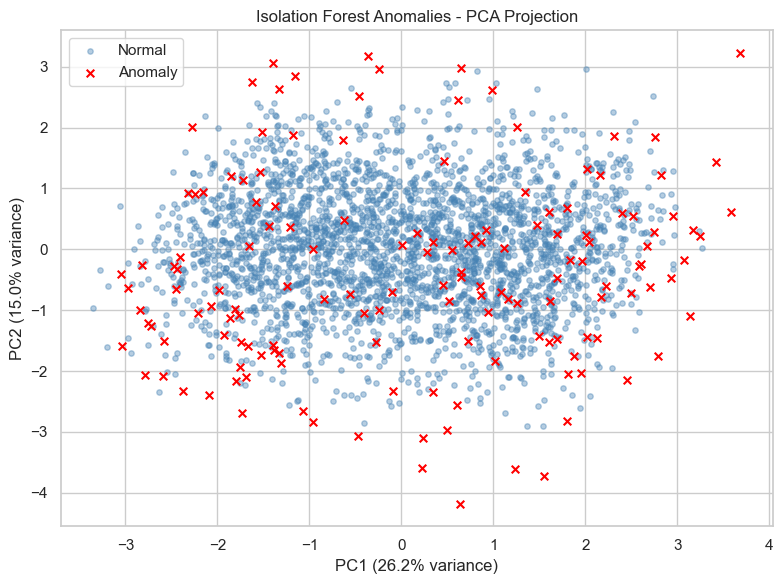

In [10]:
plt.figure(figsize=(8, 6))
is_anomaly = df["AnomalyFlag"] == "Yes"
plt.scatter(pca_coords[~is_anomaly, 0], pca_coords[~is_anomaly, 1], c="steelblue", alpha=0.4, s=15, label="Normal")
plt.scatter(pca_coords[is_anomaly, 0], pca_coords[is_anomaly, 1], c="red", marker="x", s=30, label="Anomaly")
plt.xlabel(f"PC1 ({explained_variance['PC1'] * 100:.1f}% variance)")
plt.ylabel(f"PC2 ({explained_variance['PC2'] * 100:.1f}% variance)")
plt.title("Isolation Forest Anomalies - PCA Projection")
plt.legend()
plt.tight_layout()
plt.show()

### Investigating the most unusual customers

The 10 customers with the lowest anomaly score (the most unusual) are listed individually, so their raw values can be inspected rather than just their averages.

In [11]:
columns_to_show = ["CustomerID"] + cluster_features + ["Churn", "Future12MRevenueEGP", "CustomerSegment", "AnomalyScore"]

most_unusual_customers = df.sort_values("AnomalyScore").head(10)[columns_to_show].reset_index(drop=True)
most_unusual_customers

,CustomerID,TenureMonths,MonthlyUsageGB,MonthlyChargeEGP,NumServices,SupportCalls6M,LatePayments12M,SatisfactionScore,Churn,Future12MRevenueEGP,CustomerSegment,AnomalyScore
0,CUST-02046,16,443.6,743.84,6,0,4,5.0,Yes,6800.73,At-Risk / Late-Payment Customers,-0.086825
1,CUST-01949,46,95.5,292.09,1,6,3,5.0,No,3898.07,Low-Value Basic Users,-0.073941
2,CUST-01289,72,286.0,485.50,5,5,5,3.0,No,6466.82,At-Risk / Late-Payment Customers,-0.071953
3,CUST-01312,56,69.4,231.29,1,1,0,1.0,Yes,3053.47,Low-Value Basic Users,-0.068558
4,CUST-01317,56,133.0,552.62,6,6,0,1.0,Yes,5686.11,Loyal Long-Tenured Customers,-0.067763
5,CUST-00324,5,542.9,796.97,6,5,0,4.0,No,11095.19,High-Value Power Users,-0.062546
6,CUST-00461,24,251.9,325.84,1,8,0,1.0,No,2562.45,Low-Value Basic Users,-0.058711
7,CUST-00435,37,380.2,832.48,6,6,0,2.0,No,11022.07,High-Value Power Users,-0.057879
8,CUST-02887,72,379.6,381.60,1,0,0,2.0,No,4008.35,Loyal Long-Tenured Customers,-0.056865
9,CUST-00966,6,325.6,748.06,6,0,0,1.0,No,6200.64,High-Value Power Users,-0.054747


### What makes these customers unusual?

Looking at the table above, the flagged customers share one thing: **an unusual combination of values**, not necessarily extreme values on their own. For example:

- `CUST-02046`: very high usage (443.6 GB) and a high bill (743.84 EGP), but **zero** support calls - most high-usage, high-bill customers in this dataset do call support sometimes.
- `CUST-01949`: 46 months of tenure but only 95.5 GB of usage and a single service - a long-tenured customer behaving like a brand-new, light user.
- `CUST-00324` and `CUST-00435`: extremely high usage (542.9 GB and 380.2 GB) and very high bills, combined with low tenure (5 and 37 months) and, for `CUST-00324`, 5 support calls despite a short tenure.
- Several others combine the maximum number of services (6) with **zero** support calls and **zero** late payments - an unusually "frictionless" pattern compared to most customers with that many services.

**Important: this does not mean these customers are committing fraud or that their data is wrong.** Isolation Forest only reports statistical unusualness relative to the rest of the dataset. There are several equally plausible explanations:

- They could be genuinely unusual but perfectly legitimate customers (a power user who never needs support, a long-tenured customer who simply uses the service lightly).
- They could reflect a data entry or system issue (for example, a support-call count that was not logged correctly).
- They could be an early signal of a billing dispute, a technical issue, or a customer about to churn or complain, worth a manual look.

The correct next step is for someone on the business side to **review these specific accounts**, not to label them automatically.

## 6. Final Interpretation

### PCA results

The two principal components together explain about **41.2%** of the total variance in the 7 standardized behavioral variables (PC1: 26.2%, PC2: 15.0%). This is a useful but incomplete 2D summary of a 7-dimensional space - segments that look like they overlap on this plot may still be well separated once all 7 variables are considered, and vice versa.

### Isolation Forest results

With `contamination=0.05`, **150 of the 3,000 customers (5%)** were flagged as anomalies. Compared with the other 2,850 customers, anomalies have:

- **Longer average tenure** (38.58 vs 24.85 months)
- **More late payments** (1.99 vs 1.06)
- **Lower satisfaction** (2.95 vs 3.51)
- **A slightly higher churn rate** (21.33% vs 17.96%) and **slightly higher average future revenue** (5,576.83 vs 5,349.80 EGP)

Anomalies are not concentrated in one segment: they appear across all four K-Means segments (for example 43 in the At-Risk segment and 53 in the Loyal Long-Tenured segment), confirming that "unusual" here means an atypical combination of behaviors rather than simply belonging to one particular segment.

### Business meaning

- Isolation Forest is a **flagging tool, not a verdict**. It narrows 3,000 customers down to a 150-customer shortlist worth a closer, human look - for account review, billing audits, or a quick check-in call - instead of asking a business team to examine every customer.
- Because anomalies skew toward **longer tenure and lower satisfaction**, this shortlist may overlap with customers who are quietly dissatisfied rather than actively complaining, which the churn model in Part C would otherwise need extreme values on a single variable to catch.
- The flag should feed into a human review step, and the actual explanation (legitimate behavior, data issue, or an early warning sign) should be confirmed per account, not assumed from the model alone.

## 7. Final Checklist

**Part F - PCA & Anomaly Detection**
- [x] PCA applied with 2 components to the standardized segmentation data
- [x] Explained variance reported (per component and combined)
- [x] PC1/PC2 scatter plot colored by K-Means segment
- [x] Isolation Forest applied
- [x] Unusual customers investigated individually, with concrete, data-based observations
- [x] Anomalies are not automatically labeled as fraud; alternative explanations are discussed